# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

### Implementación y resultados

En la celda de código siguiente carga Iris y genera la tabla y el gráfico solicitados.


### Idea inicial registrada durante la exploración

Antes de ver las columnas, pensaba que los datos podían incluir familia, género, especie o color de las flores. Al inspeccionar la tabla encontré cuatro medidas numéricas y una columna `target`. Esta fue mi idea durante la exploración; no es una predicción nueva hecha después del resultado.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# Cargamos Iris
iris_data = load_iris(as_frame=True)
df = iris_data.frame

# X contiene las cuatro medidas; y contiene la clase de cada flor.
X = iris_data.data
y = iris_data.target
print("Dimensiones de X (características):", X.shape)
print("Dimensiones de y (clases):", y.shape)

# Tabla solicitada: cinco ejemplos del conjunto.
display(df.tail(5))


Dimensiones de X (características): (150, 4)
Dimensiones de y (clases): (150,)


sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
6.7,3.0,5.2,2.3,2
6.3,2.5,5.0,1.9,2
6.5,3.0,5.2,2.0,2
6.2,3.4,5.4,2.3,2
5.9,3.0,5.1,1.8,2


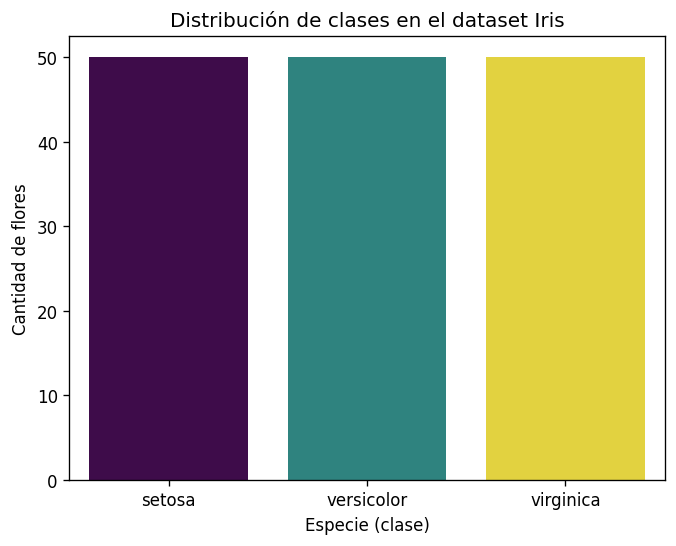

In [ ]:
# Cada barra cuenta cuántas flores pertenecen a una clase.
sns.countplot(
    data=df,
    x="target",
    hue="target",
    palette="viridis",
    legend=False,
)
plt.xticks(ticks=range(len(iris_data.target_names)), labels=iris_data.target_names)
plt.title("Distribución de clases en el dataset Iris")
plt.xlabel("Especie (clase)")
plt.ylabel("Cantidad de flores")
plt.show()


### Descripción del conjunto de datos

- **Qué representa cada instancia:** Cada fila representa una flor Iris individual.

- **Características y significado:** largo y ancho del sépalo, y largo y ancho del pétalo. Las cuatro medidas están expresadas en centímetros.

In [22]:
iris_data.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

- **Clases y cantidad de ejemplos:** `target` usa los códigos 0, 1 y 2 para representar, respectivamente, setosa, versicolor y virginica. 

- Hay 50 flores de cada especie, como muestra el gráfico.

- **Dimensiones de X e y:** `X` tiene forma `(150, 4)`: 150 flores y cuatro características. `y` tiene forma `(150,)`: una etiqueta de clase por flor.

### Interpretación de la exploración

Cada instancia es una flor y cada característica es una medida de esa flor. La clase es la especie que queremos predecir a partir de esas medidas. Los códigos 0, 1 y 2 identifican especies; no indican tamaños ni un orden entre ellas. El gráfico muestra 50 flores por especie, así que Iris está balanceado. Esto describe la distribución de clases, pero todavía no demuestra qué modelo podrá distinguirlas mejor.

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
   - **Mi predicción:** Espero que la regresión logística, la SVM lineal y el MLP sean los más sensibles a la escala, porque sus pesos y su optimización dependen de la magnitud de las entradas. En cambio, los árboles y sus ensambles suelen depender del orden y de los umbrales de cada característica, así que espero que el escalamiento les afecte menos.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
   - **Mi predicción:** Apostaría por la regresión logística y la SVM lineal: ambas construyen fronteras lineales. Espero que un árbol profundo o un MLP puedan formar fronteras más detalladas, aunque eso no garantiza que clasifiquen mejor flores nuevas.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
   - **Mi predicción:** No puedo saberlo solo por el nombre del algoritmo. El resultado depende de cómo se separen las especies en estas medidas, de la complejidad elegida y de cuánto se ajuste cada modelo a los ejemplos de entrenamiento. La validación ayudará a elegir; la prueba dará una estimación final con datos que no se usaron para ajustar.

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Implementación

La comparación usa las mismas particiones para todos los modelos. El escalador está dentro de cada pipeline para que aprenda medias y desviaciones solo al entrenar. Se elegirá la configuración con mejor F1 macro en validación, porque da el mismo peso a las tres especies; accuracy servirá como desempate. Después de fijarla, se volverá a entrenar con entrenamiento y validación juntos y se evaluará una sola vez en prueba.

### Preparación común

Primero separamos las 150 flores: 90 para entrenamiento, 30 para validación y 30 para prueba. `stratify` conserva la proporción de especies. Todos los modelos usarán estas mismas particiones.

Cada modelo tendrá su propio `Pipeline` con `StandardScaler`: al llamar a `fit`, el escalador aprende las medias y desviaciones con los datos de entrenamiento. Al predecir en validación, usa esas mismas medidas. Así evitamos que la transformación aprenda información de los conjuntos reservados.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

# Separamos antes de ajustar cualquier transformación y conservamos las proporciones de clase.
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42
)
X_validation, X_test, y_validation, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=42
)
print(
    f"Particiones: entrenamiento={len(y_train)}, "
    f"validación={len(y_validation)}, prueba={len(y_test)}"
)


# Guardaremos aquí la configuración elegida de cada clasificador.
best_validation = {}

def validation_metrics(prediction):
    return {
        "Accuracy": accuracy_score(y_validation, prediction),
        "F1 macro": f1_score(y_validation, prediction, average="macro"),
    }

Particiones: entrenamiento=90, validación=30, prueba=30


### Gaussian Naive Bayes

Este modelo estima una distribución gaussiana para cada característica dentro de cada especie. Supone que las características son independientes una vez conocida la clase. `var_smoothing` añade un pequeño suavizado a las varianzas para evitar problemas numéricos.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [24]:
nb_initial_params = {'var_smoothing': 1e-09}
nb_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", GaussianNB().set_params(**nb_initial_params)),
])
print("Configuración inicial:", nb_initial_params)

Configuración inicial: {'var_smoothing': 1e-09}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [25]:
nb_initial.fit(X_train, y_train)
nb_initial_prediction = nb_initial.predict(X_validation)
nb_initial_metrics = validation_metrics(nb_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Gaussian Naive Bayes',
    **nb_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Gaussian Naive Bayes,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Solo cambiaremos el suavizado; el resto del modelo se mantiene igual. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [26]:
nb_grid = {'var_smoothing': [1e-07, 1e-09, 1e-11]}
nb_candidates = []
for order, params in enumerate(ParameterGrid(nb_grid)):
    if params == nb_initial_params:
        candidate = nb_initial
        prediction = nb_initial_prediction
    else:
        candidate = clone(nb_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    nb_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in nb_candidates
]).round(3))

best_validation['Gaussian Naive Bayes'] = max(
    nb_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Gaussian Naive Bayes']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,{'var_smoothing': 1e-07},0.933,0.933
1,{'var_smoothing': 1e-09},0.933,0.933
2,{'var_smoothing': 1e-11},0.933,0.933


Configuración congelada: {'var_smoothing': 1e-07}


### Regresión logística

La regresión logística multiclase combina las cuatro medidas para estimar la probabilidad de cada especie. Sus fronteras de decisión son lineales. `C` controla la regularización: un valor menor limita más los pesos.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [27]:
logistic_initial_params = {'C': 1.0}
logistic_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000, random_state=42).set_params(**logistic_initial_params)),
])
print("Configuración inicial:", logistic_initial_params)

Configuración inicial: {'C': 1.0}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [28]:
logistic_initial.fit(X_train, y_train)
logistic_initial_prediction = logistic_initial.predict(X_validation)
logistic_initial_metrics = validation_metrics(logistic_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Regresión logística',
    **logistic_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Regresión logística,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Compararemos tres valores de `C` para ver cuánto conviene limitar los pesos. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [29]:
logistic_grid = {'C': [0.1, 1.0, 10.0]}
logistic_candidates = []
for order, params in enumerate(ParameterGrid(logistic_grid)):
    if params == logistic_initial_params:
        candidate = logistic_initial
        prediction = logistic_initial_prediction
    else:
        candidate = clone(logistic_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    logistic_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in logistic_candidates
]).round(3))

best_validation['Regresión logística'] = max(
    logistic_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Regresión logística']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,{'C': 0.1},0.867,0.865
1,{'C': 1.0},0.933,0.933
2,{'C': 10.0},0.933,0.933


Configuración congelada: {'C': 1.0}


### SVM lineal

La SVM lineal busca fronteras que separen las clases con margen. `C` controla cuánto penaliza los errores durante el entrenamiento: un valor mayor les da más importancia. Sus puntuaciones de decisión no son probabilidades.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [30]:
svm_initial_params = {'C': 1.0}
svm_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(max_iter=10000, random_state=42).set_params(**svm_initial_params)),
])
print("Configuración inicial:", svm_initial_params)

Configuración inicial: {'C': 1.0}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [31]:
svm_initial.fit(X_train, y_train)
svm_initial_prediction = svm_initial.predict(X_validation)
svm_initial_metrics = validation_metrics(svm_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'SVM lineal',
    **svm_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,SVM lineal,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Probaremos tres valores de `C`, usando las métricas de validación para elegir. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [32]:
svm_grid = {'C': [0.1, 1.0, 10.0]}
svm_candidates = []
for order, params in enumerate(ParameterGrid(svm_grid)):
    if params == svm_initial_params:
        candidate = svm_initial
        prediction = svm_initial_prediction
    else:
        candidate = clone(svm_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    svm_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in svm_candidates
]).round(3))

best_validation['SVM lineal'] = max(
    svm_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['SVM lineal']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,{'C': 0.1},0.833,0.829
1,{'C': 1.0},0.933,0.933
2,{'C': 10.0},0.933,0.933


Configuración congelada: {'C': 10.0}


### Árbol de decisión

El árbol clasifica mediante preguntas sobre las medidas, por ejemplo si el ancho del pétalo supera un umbral. `max_depth` limita cuántos niveles puede tener y `min_samples_leaf` exige un mínimo de flores en cada hoja. Un árbol muy profundo puede ajustarse demasiado al entrenamiento.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [33]:
tree_initial_params = {'max_depth': None, 'min_samples_leaf': 1}
tree_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(random_state=42).set_params(**tree_initial_params)),
])
print("Configuración inicial:", tree_initial_params)

Configuración inicial: {'max_depth': None, 'min_samples_leaf': 1}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [34]:
tree_initial.fit(X_train, y_train)
tree_initial_prediction = tree_initial.predict(X_validation)
tree_initial_metrics = validation_metrics(tree_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Árbol de decisión',
    **tree_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Árbol de decisión,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Compararemos árboles de distinta profundidad y dos tamaños mínimos de hoja. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [35]:
tree_grid = {'max_depth': [2, 3, None], 'min_samples_leaf': [3, 1]}
tree_candidates = []
for order, params in enumerate(ParameterGrid(tree_grid)):
    if params == tree_initial_params:
        candidate = tree_initial
        prediction = tree_initial_prediction
    else:
        candidate = clone(tree_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    tree_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in tree_candidates
]).round(3))

best_validation['Árbol de decisión'] = max(
    tree_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Árbol de decisión']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,"{'max_depth': 2, 'min_samples_leaf': 3}",0.900,0.900
1,"{'max_depth': 2, 'min_samples_leaf': 1}",0.900,0.900
2,"{'max_depth': 3, 'min_samples_leaf': 3}",0.967,0.967
3,"{'max_depth': 3, 'min_samples_leaf': 1}",0.967,0.967
4,"{'max_depth': None, 'min_samples_leaf': 3}",0.967,0.967
5,"{'max_depth': None, 'min_samples_leaf': 1}",0.933,0.933


Configuración congelada: {'max_depth': 3, 'min_samples_leaf': 3}


### Random Forest

Random Forest combina las predicciones de varios árboles. Cada árbol usa una muestra aleatoria del entrenamiento y considera subconjuntos de características al dividir. Esta variedad ayuda a reducir la variación que tendría un solo árbol. `n_estimators` indica cuántos árboles se construyen.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [36]:
forest_initial_params = {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}
forest_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_jobs=-1, random_state=42).set_params(**forest_initial_params)),
])
print("Configuración inicial:", forest_initial_params)

Configuración inicial: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [37]:
forest_initial.fit(X_train, y_train)
forest_initial_prediction = forest_initial.predict(X_validation)
forest_initial_metrics = validation_metrics(forest_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Random Forest',
    **forest_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Random Forest,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Probaremos 100 o 200 árboles, junto con límites de profundidad y tamaño de hoja. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [38]:
forest_grid = {'n_estimators': [100, 200], 'max_depth': [3, 5, None], 'min_samples_leaf': [2, 1]}
forest_candidates = []
for order, params in enumerate(ParameterGrid(forest_grid)):
    if params == forest_initial_params:
        candidate = forest_initial
        prediction = forest_initial_prediction
    else:
        candidate = clone(forest_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    forest_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in forest_candidates
]).round(3))

best_validation['Random Forest'] = max(
    forest_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Random Forest']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,"{'max_depth': 3, 'min_samples_leaf': 2, 'n_est...",0.933,0.933
1,"{'max_depth': 3, 'min_samples_leaf': 2, 'n_est...",0.933,0.933
2,"{'max_depth': 3, 'min_samples_leaf': 1, 'n_est...",0.933,0.933
3,"{'max_depth': 3, 'min_samples_leaf': 1, 'n_est...",0.933,0.933
4,"{'max_depth': 5, 'min_samples_leaf': 2, 'n_est...",0.933,0.933
5,"{'max_depth': 5, 'min_samples_leaf': 2, 'n_est...",0.933,0.933
6,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est...",0.933,0.933
7,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est...",0.933,0.933
8,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",0.933,0.933
9,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",0.933,0.933


Configuración congelada: {'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}


### Gradient Boosting

Gradient Boosting construye árboles en secuencia: cada nuevo árbol intenta mejorar lo que el conjunto todavía predice mal, siguiendo la función de pérdida. `learning_rate` controla el aporte de cada árbol, `n_estimators` la cantidad de etapas y `max_depth` la complejidad de cada árbol.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [39]:
boosting_initial_params = {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3}
boosting_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", GradientBoostingClassifier(random_state=42).set_params(**boosting_initial_params)),
])
print("Configuración inicial:", boosting_initial_params)

Configuración inicial: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [40]:
boosting_initial.fit(X_train, y_train)
boosting_initial_prediction = boosting_initial.predict(X_validation)
boosting_initial_metrics = validation_metrics(boosting_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'Gradient Boosting',
    **boosting_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,Gradient Boosting,0.933,0.933


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Compararemos dos cantidades de árboles, dos tasas de aprendizaje y tres profundidades pequeñas. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [41]:
boosting_grid = {'n_estimators': [50, 100], 'learning_rate': [0.05, 0.1], 'max_depth': [1, 2, 3]}
boosting_candidates = []
for order, params in enumerate(ParameterGrid(boosting_grid)):
    if params == boosting_initial_params:
        candidate = boosting_initial
        prediction = boosting_initial_prediction
    else:
        candidate = clone(boosting_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    boosting_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in boosting_candidates
]).round(3))

best_validation['Gradient Boosting'] = max(
    boosting_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['Gradient Boosting']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,"{'learning_rate': 0.05, 'max_depth': 1, 'n_est...",0.967,0.967
1,"{'learning_rate': 0.05, 'max_depth': 1, 'n_est...",0.933,0.933
2,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.967,0.967
3,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.967,0.967
4,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.967,0.967
5,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.933,0.933
6,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",0.933,0.933
7,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",0.933,0.933
8,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.967,0.967
9,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.933,0.933


Configuración congelada: {'learning_rate': 0.05, 'max_depth': 1, 'n_estimators': 50}


### MLP

El MLP tiene una capa oculta que transforma las medidas mediante una activación no lineal. Esto le permite formar fronteras más complejas que un modelo lineal. `hidden_layer_sizes` define las neuronas de esa capa y `alpha` controla la regularización de los pesos. Con `early_stopping`, reserva internamente una parte del entrenamiento para decidir cuándo detenerse; no usa nuestra partición externa de validación para entrenar.

#### Paso 1. Configuración inicial

Definimos los hiperparámetros iniciales y colocamos el escalador antes del clasificador.

In [42]:
mlp_initial_params = {'hidden_layer_sizes': (16,), 'alpha': 0.0001}
mlp_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(solver="adam", max_iter=2000, early_stopping=True,
        n_iter_no_change=30, random_state=42).set_params(**mlp_initial_params)),
])
print("Configuración inicial:", mlp_initial_params)

Configuración inicial: {'hidden_layer_sizes': (16,), 'alpha': 0.0001}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

`fit` aprende con las flores de entrenamiento. Luego `predict` clasifica las de validación: accuracy cuenta la proporción de aciertos y F1 macro promedia el F1 de las tres especies, dando a cada una el mismo peso.

In [43]:
mlp_initial.fit(X_train, y_train)
mlp_initial_prediction = mlp_initial.predict(X_validation)
mlp_initial_metrics = validation_metrics(mlp_initial_prediction)
display(pd.DataFrame([{
    "Modelo": 'MLP',
    **mlp_initial_metrics,
}]).round(3))

,Modelo,Accuracy,F1 macro
0,MLP,0.733,0.707


#### Pasos 4 y 5. Ajustes limitados y configuración congelada

Mantendremos una sola capa oculta y compararemos tres tamaños y dos niveles de regularización. Cada candidato se entrena con la misma partición de entrenamiento y se compara en validación. Elegimos el mayor F1 macro; si empatan, usamos accuracy y después el orden de los candidatos. Una vez elegida la configuración, la guardamos sin consultar la prueba.

In [44]:
mlp_grid = {'hidden_layer_sizes': [(8,), (16,), (32,)], 'alpha': [0.01, 0.0001]}
mlp_candidates = []
for order, params in enumerate(ParameterGrid(mlp_grid)):
    if params == mlp_initial_params:
        candidate = mlp_initial
        prediction = mlp_initial_prediction
    else:
        candidate = clone(mlp_initial)
        candidate.set_params(**{f"classifier__{param}": value for param, value in params.items()})
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_validation)
    mlp_candidates.append({
        "Parámetros": params,
        **validation_metrics(prediction),
        "Orden": order,
        "pipeline": candidate,
        "predicción_validación": prediction,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "Accuracy", "F1 macro"]}
    for row in mlp_candidates
]).round(3))

best_validation['MLP'] = max(
    mlp_candidates,
    key=lambda row: (row["F1 macro"], row["Accuracy"], -row["Orden"]),
)
print("Configuración congelada:", best_validation['MLP']["Parámetros"])

,Parámetros,Accuracy,F1 macro
0,"{'alpha': 0.01, 'hidden_layer_sizes': (8,)}",0.300,0.222
1,"{'alpha': 0.01, 'hidden_layer_sizes': (16,)}",0.733,0.707
2,"{'alpha': 0.01, 'hidden_layer_sizes': (32,)}",0.700,0.651
3,"{'alpha': 0.0001, 'hidden_layer_sizes': (8,)}",0.300,0.222
4,"{'alpha': 0.0001, 'hidden_layer_sizes': (16,)}",0.733,0.707
5,"{'alpha': 0.0001, 'hidden_layer_sizes': (32,)}",0.700,0.651


Configuración congelada: {'alpha': 0.01, 'hidden_layer_sizes': (16,)}


## Resultados

### Paso 6. Evaluación final en prueba

Ya elegimos las siete configuraciones usando validación. Ahora volvemos a entrenar cada una con las 120 flores de entrenamiento y validación juntas. El escalador también se vuelve a ajustar con esas 120 flores. Las 30 de prueba siguen separadas y solo se usan para la evaluación final.

La tabla reúne modelo, transformación, hiperparámetros, accuracy de prueba y F1 macro de prueba, como pide el profesor. Estos resultados no se usan para cambiar otra vez los hiperparámetros.

In [45]:
# Las configuraciones quedan congeladas. Reentrenamos con entrenamiento + validación;
# la prueba sigue separada y no participa en la selección.
X_development = pd.concat([X_train, X_validation])
y_development = pd.concat([y_train, y_validation])
final_models = {}
predictions_test = {}
for model_name, selected in best_validation.items():
    final_model = clone(selected["pipeline"])
    final_model.fit(X_development, y_development)
    final_models[model_name] = final_model
    predictions_test[model_name] = final_model.predict(X_test)

# Tabla final: se informa la prueba, pero no se vuelve a ajustar con ella.
def format_params(model_name, params):
    reported = dict(params)
    if model_name == "MLP":
        reported.update({"solver": "adam", "early_stopping": True})
    return ", ".join(f"{name}={value}" for name, value in reported.items())

test_rows = []
for model_name, selected in best_validation.items():
    prediction = predictions_test[model_name]
    test_rows.append({
        "Modelo": model_name,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": format_params(model_name, selected["Parámetros"]),
        "Accuracy de prueba": accuracy_score(y_test, prediction),
        "F1 macro de prueba": f1_score(y_test, prediction, average="macro"),
    })
results_test = pd.DataFrame(test_rows)
print("Resultados finales en el conjunto de prueba:")
display(results_test.round({"Accuracy de prueba": 3, "F1 macro de prueba": 3}))

Resultados finales en el conjunto de prueba:


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,var_smoothing=1e-07,0.933,0.933
1,Regresión logística,StandardScaler,C=1.0,0.933,0.933
2,SVM lineal,StandardScaler,C=10.0,0.933,0.933
3,Árbol de decisión,StandardScaler,"max_depth=3, min_samples_leaf=3",0.933,0.933
4,Random Forest,StandardScaler,"max_depth=3, min_samples_leaf=2, n_estimators=100",0.933,0.933
5,Gradient Boosting,StandardScaler,"learning_rate=0.05, max_depth=1, n_estimators=50",0.933,0.933
6,MLP,StandardScaler,"alpha=0.01, hidden_layer_sizes=(16,), solver=a...",0.867,0.861


### Matrices de confusión

Las filas indican la especie real y las columnas la predicha. Los valores de la diagonal son aciertos; los que quedan fuera son confusiones entre especies. Usamos el mismo orden de clases y las mismas flores de prueba para Naive Bayes, SVM y MLP.

#### Gaussian Naive Bayes

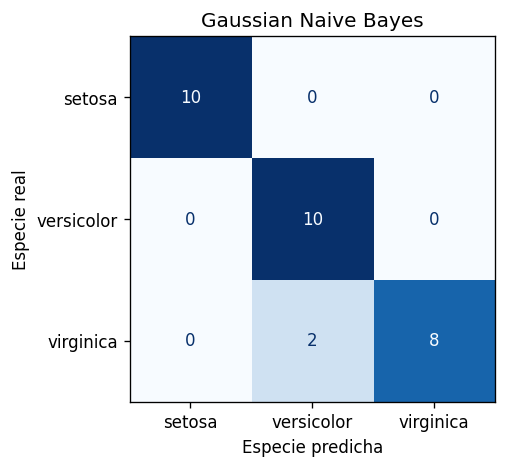

In [ ]:
fig, axis = plt.subplots(figsize=(5, 4))
matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_test['Gaussian Naive Bayes'],
    labels=np.arange(len(iris_data.target_names)),
    display_labels=iris_data.target_names,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=axis,
)
axis.set_title('Gaussian Naive Bayes')
axis.set_xlabel("Especie predicha")
axis.set_ylabel("Especie real")
plt.tight_layout()
plt.show()

#### SVM lineal

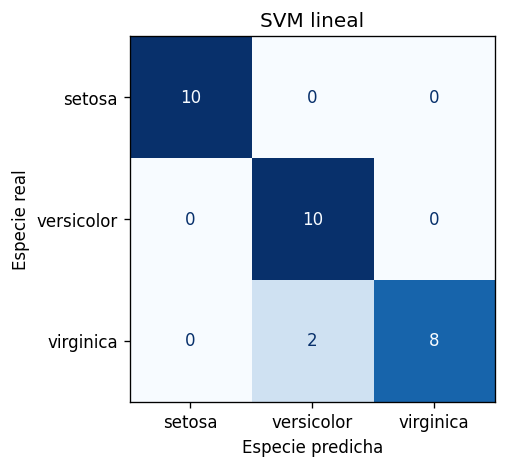

In [ ]:
fig, axis = plt.subplots(figsize=(5, 4))
matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_test['SVM lineal'],
    labels=np.arange(len(iris_data.target_names)),
    display_labels=iris_data.target_names,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=axis,
)
axis.set_title('SVM lineal')
axis.set_xlabel("Especie predicha")
axis.set_ylabel("Especie real")
plt.tight_layout()
plt.show()

#### MLP

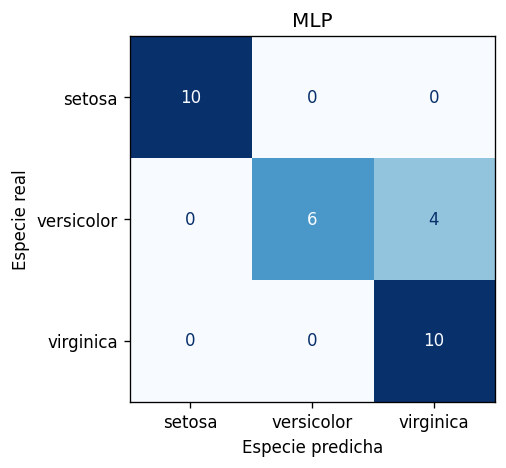

In [ ]:
fig, axis = plt.subplots(figsize=(5, 4))
matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_test['MLP'],
    labels=np.arange(len(iris_data.target_names)),
    display_labels=iris_data.target_names,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=axis,
)
axis.set_title('MLP')
axis.set_xlabel("Especie predicha")
axis.set_ylabel("Especie real")
plt.tight_layout()
plt.show()

### Dos ejemplos mal clasificados

Buscamos dos flores distintas cuya predicción no coincida con su especie real. Mostramos sus cuatro medidas para poder discutir la confusión. Si no hubiera suficientes errores en prueba, completaríamos los ejemplos con validación, indicando de qué partición viene cada uno.

In [ ]:
# Elegimos dos errores reales de prueba de modelos distintos si hace falta.
# Si en prueba no hubiera dos casos distintos, completamos con errores de validación.
error_examples = []
for partition_name, features, actual, predictions_by_model in [
    ("prueba", X_test, np.asarray(y_test), predictions_test),
    (
        "validación",
        X_validation,
        np.asarray(y_validation),
        {name: row["predicción_validación"] for name, row in best_validation.items()},
    ),
]:
    seen_indices = {row["Índice de flor"] for row in error_examples}
    for model_name in best_validation:
        prediction = np.asarray(predictions_by_model[model_name])
        for position in np.flatnonzero(prediction != actual):
            flower_index = int(features.index[position])
            if flower_index in seen_indices:
                continue
            feature_values = features.iloc[position]
            error_examples.append({
                "Partición": partition_name,
                "Modelo": model_name,
                "Índice de flor": flower_index,
                "Especie real": iris_data.target_names[int(actual[position])],
                "Especie predicha": iris_data.target_names[int(prediction[position])],
                **{column: feature_values[column] for column in X.columns},
            })
            seen_indices.add(flower_index)
            if len(error_examples) == 2:
                break
        if len(error_examples) == 2:
            break
    if len(error_examples) == 2:
        break

print("Dos ejemplos de errores para revisar (primero se buscan en prueba):")
if error_examples:
    display(pd.DataFrame(error_examples).round(2))
else:
    print("No aparecieron errores en prueba ni validación; no hay casos mal clasificados que describir.")

Dos ejemplos de errores para revisar (primero se buscan en prueba):


Partición,Modelo,Índice de flor,Especie real,Especie predicha,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
prueba,Gaussian Naive Bayes,134,virginica,versicolor,6.1,2.6,5.6,1.4
prueba,Gaussian Naive Bayes,133,virginica,versicolor,6.3,2.8,5.1,1.5


## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
   - En validación, el árbol y Gradient Boosting llegaron a 0.967. En la prueba, seis modelos empataron: Naive Bayes, regresión logística, SVM lineal, árbol, Random Forest y Gradient Boosting obtuvieron 0.933 en accuracy y F1 macro (28 aciertos de 30). No hay un ganador único en esta partición. El MLP obtuvo 0.867 de accuracy y 0.861 de F1 macro.

2. ¿Cuál fue el modelo más sencillo de programar?
   - Para mí, Gaussian Naive Bayes fue el más sencillo de configurar: estima cómo se distribuyen las características en cada clase y solo ajusté su nivel de suavizado (`var_smoothing`). El código de comparación comparte los mismos pasos para todos, así que esta sencillez se refiere a la configuración del modelo. Que sea sencillo no significa que tenga que ganar.

3. ¿Accuracy y F1 macro cuentan la misma historia?
   - Aquí cuentan una historia parecida: los seis modelos empatados tienen ambas métricas en 0.933; el MLP queda algo más abajo en las dos. No son la misma medida: accuracy resume cuántas predicciones fueron correctas, mientras que F1 macro calcula un F1 para cada especie y luego los promedia. En la matriz del MLP, por ejemplo, cuatro versicolor se confundieron con virginica; F1 macro ayuda a ver el desempeño por clase. Como la partición de prueba tiene diez flores de cada especie, ninguna clase domina el conteo total.

4. ¿Cuál es la diferencia entre las métricas macro y micro?
   - Macro calcula la métrica por separado para cada clase y luego promedia, dando el mismo peso a setosa, versicolor y virginica. Micro suma primero los aciertos y errores de todas las clases y calcula una métrica global. En una clasificación multiclase de una sola etiqueta como esta, F1 micro coincide con accuracy. En este experimento el conjunto está balanceado, así que no hay una especie con muchas más muestras que arrastre el promedio.

5. ¿Qué aporta el MLP frente a un modelo lineal?
   - La capa oculta del MLP puede transformar las medidas y, con una activación no lineal, representar fronteras más curvas que una regresión logística o una SVM lineal. Pero esa capacidad extra no se convirtió en mejor resultado aquí: el MLP quedó por debajo de los modelos lineales en la prueba y confundió cuatro versicolor con virginica. En esta partición, su mayor complejidad no trajo una ventaja medible; con un solo reparto no concluiría que siempre será peor.

**Análisis de errores:** Los dos ejemplos impresos son errores de Gaussian Naive Bayes: eran virginica y el modelo los predijo como versicolor. Tienen ancho de pétalo de 1.4 y 1.5 cm, respectivamente, una medida que ayuda a entender por qué el modelo pudo acercarlos a esa clase. Es una explicación compatible con esos ejemplos, no una causa demostrada: el modelo combina las cuatro medidas y Naive Bayes además supone independencia condicional entre características. Dos errores no bastan para afirmar que una medida concreta provocó la confusión.

**Alcance de la comparación:** Todos los modelos recibieron características estandarizadas, como pide la práctica. Por eso este experimento no mide qué habría pasado sin escalamiento y no permite atribuir las diferencias de rendimiento a esa transformación. La prueba tiene solo 30 flores; un acierto cambia accuracy en unos 3.3 puntos porcentuales. Las diapositivas de clase recuerdan que validación sirve para elegir y prueba para estimar el resultado final, no para abrir otra ronda de ajustes.


# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

**Predicción propuesta para revisar:** No espero que un modelo más flexible siempre tenga menos error en datos nuevos. Puede aprender patrones útiles, pero también ajustarse al ruido del entrenamiento. La regularización y la validación deberían ayudar a elegir una complejidad que generalice. Esta es una propuesta de la asistencia de IA; debo revisarla y expresar mi propia expectativa antes de ejecutar el experimento.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

### Conocer los datos

Cada fila corresponde a uno de los 442 pacientes. El objetivo es una medida cuantitativa de la progresión de la enfermedad un año después de las mediciones iniciales. Es un valor numérico; no estamos intentando predecir una especie o una categoría como en Iris. La descripción no especifica una unidad clínica para ese objetivo, así que los errores se expresarán en unidades de su escala.

Las diez variables son edad (`age`), sexo codificado (`sex`), índice de masa corporal (`bmi`), presión arterial media (`bp`) y seis mediciones de suero: colesterol total (`s1`), LDL (`s2`), HDL (`s3`), relación colesterol total/HDL (`s4`), una variable descrita como posiblemente el logaritmo de triglicéridos (`s5`) y glucosa (`s6`). La documentación advierte que algunas definiciones originales son poco precisas.

Por defecto, `load_diabetes` centra cada característica y la divide por su desviación estándar multiplicada por la raíz del número de muestras. Esos valores no son las mediciones originales. Aquí usamos `scaled=False` para evitar ese escalamiento previo sobre todo el dataset y después ajustamos nuestras transformaciones con entrenamiento. Esto no elimina transformaciones propias de una variable como `s5`, ni convierte el código de sexo en una cantidad física.

Fuente: [documentación de Diabetes en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

diabetes_data = load_diabetes(as_frame=True, scaled=False)
X_diabetes = diabetes_data.data
y_diabetes = diabetes_data.target
print("X:", X_diabetes.shape, "y:", y_diabetes.shape)
display(diabetes_data.frame.head(5))
# DESCR describe también el escalamiento de la carga predeterminada.
# Nuestra carga lo desactiva explícitamente con scaled=False.
print(diabetes_data.DESCR)

X: (442, 10) y: (442,)


age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

### Preparación común y criterio de selección

Usaremos aproximadamente 60 % para entrenamiento, 20 % para validación y 20 % para prueba, con la misma separación para los ocho regresores. En regresión no hay clases que debamos balancear con `stratify`.

Elegiremos los hiperparámetros por el menor RMSE de validación, usando MAE para desempatar y el orden de candidatos si persiste el empate. RMSE da más peso a los errores grandes. También mostraremos MAE y R² para no reducir la comparación a una sola cifra. La prueba queda reservada hasta congelar todas las configuraciones.

Usaremos `StandardScaler` para los modelos lineales, kNN y MLP. Los árboles y sus ensambles comparan umbrales de cada variable y no necesitan este escalamiento. El objetivo solo se estandariza para el MLP mediante `TransformedTargetRegressor`, que aprende la transformación al entrenar y la invierte automáticamente al predecir.

In [ ]:
X_reg_train, X_reg_rest, y_reg_train, y_reg_rest = train_test_split(
    X_diabetes, y_diabetes, test_size=0.40, random_state=42
)
X_reg_validation, X_reg_test, y_reg_validation, y_reg_test = train_test_split(
    X_reg_rest, y_reg_rest, test_size=0.50, random_state=42
)
print(f"Entrenamiento: {len(y_reg_train)}, validación: {len(y_reg_validation)}, prueba: {len(y_reg_test)}")

best_reg_validation = {}
reg_candidates = {}

def regression_metrics(actual, prediction):
    return {
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": root_mean_squared_error(actual, prediction),
        "R²": r2_score(actual, prediction),
    }

Entrenamiento: 265, validación: 88, prueba: 89


### Regresión lineal

La regresión lineal estima el objetivo sumando las contribuciones de las diez características y un intercepto. Minimiza el error cuadrático de entrenamiento. Es nuestra referencia de un modelo lineal sin penalización.

#### Paso 1. Configuración inicial

In [ ]:
linear_initial_params = {}
linear_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression().set_params(**linear_initial_params)),
])
print("Configuración inicial:", linear_initial_params)

Configuración inicial: {}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

Entrenamos con `fit` y predecimos con `predict`. MAE resume el tamaño medio de los errores absolutos; RMSE aumenta más cuando hay errores grandes; R² compara el error cuadrático con usar la media del conjunto evaluado.

In [ ]:
linear_initial.fit(X_reg_train, y_reg_train)
linear_initial_prediction = linear_initial.predict(X_reg_validation)
display(pd.DataFrame([{
    "Modelo": 'Regresión lineal',
    **regression_metrics(y_reg_validation, linear_initial_prediction),
}]).round(3))

Modelo,MAE,RMSE,R²
Regresión lineal,38.221,49.15,0.581


#### Pasos 4 y 5. Ajustes y configuración congelada

No tiene una intensidad de penalización que ajustar en este experimento. Conservamos su configuración inicial y registramos el resultado de validación. Elegimos usando solamente validación; la prueba todavía no participa.

In [ ]:
linear_grid = {}
linear_candidates = []
for order, params in enumerate(ParameterGrid(linear_grid)):
    if params == linear_initial_params:
        candidate = linear_initial
        prediction = linear_initial_prediction
    else:
        candidate = clone(linear_initial)
        candidate.set_params(**{f"regressor__{param}": value for param, value in params.items()})
        candidate.fit(X_reg_train, y_reg_train)
        prediction = candidate.predict(X_reg_validation)
    train_metrics = regression_metrics(y_reg_train, candidate.predict(X_reg_train))
    linear_candidates.append({
        "Parámetros": params,
        **regression_metrics(y_reg_validation, prediction),
        "RMSE de entrenamiento": train_metrics["RMSE"],
        "Orden": order,
        "modelo": candidate,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "RMSE de entrenamiento", "MAE", "RMSE", "R²"]}
    for row in linear_candidates
]).rename(columns={"MAE": "MAE de validación", "RMSE": "RMSE de validación", "R²": "R² de validación"}).round(3))
reg_candidates['Regresión lineal'] = linear_candidates
best_reg_validation['Regresión lineal'] = min(
    linear_candidates,
    key=lambda row: (row["RMSE"], row["MAE"], row["Orden"]),
)
print("Configuración congelada:", best_reg_validation['Regresión lineal']["Parámetros"])

Parámetros,RMSE de entrenamiento,MAE de validación,RMSE de validación,R² de validación
{},54.285,38.221,49.15,0.581


Configuración congelada: {}


### Ridge

Ridge añade una penalización L2: limita la magnitud de los coeficientes y puede estabilizarlos cuando varias variables están relacionadas. `alpha` controla la intensidad; una penalización demasiado fuerte puede producir subajuste.

#### Paso 1. Configuración inicial

In [ ]:
ridge_initial_params = {'alpha': 1.0}
ridge_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge().set_params(**ridge_initial_params)),
])
print("Configuración inicial:", ridge_initial_params)

Configuración inicial: {'alpha': 1.0}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

Entrenamos con `fit` y predecimos con `predict`. MAE resume el tamaño medio de los errores absolutos; RMSE aumenta más cuando hay errores grandes; R² compara el error cuadrático con usar la media del conjunto evaluado.

In [ ]:
ridge_initial.fit(X_reg_train, y_reg_train)
ridge_initial_prediction = ridge_initial.predict(X_reg_validation)
display(pd.DataFrame([{
    "Modelo": 'Ridge',
    **regression_metrics(y_reg_validation, ridge_initial_prediction),
}]).round(3))

Modelo,MAE,RMSE,R²
Ridge,38.294,49.203,0.58


#### Pasos 4 y 5. Ajustes y configuración congelada

Compararemos seis intensidades de penalización. Más adelante veremos sus coeficientes y sus errores de entrenamiento y validación. Elegimos usando solamente validación; la prueba todavía no participa.

In [ ]:
ridge_grid = {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}
ridge_candidates = []
for order, params in enumerate(ParameterGrid(ridge_grid)):
    if params == ridge_initial_params:
        candidate = ridge_initial
        prediction = ridge_initial_prediction
    else:
        candidate = clone(ridge_initial)
        candidate.set_params(**{f"regressor__{param}": value for param, value in params.items()})
        candidate.fit(X_reg_train, y_reg_train)
        prediction = candidate.predict(X_reg_validation)
    train_metrics = regression_metrics(y_reg_train, candidate.predict(X_reg_train))
    ridge_candidates.append({
        "Parámetros": params,
        **regression_metrics(y_reg_validation, prediction),
        "RMSE de entrenamiento": train_metrics["RMSE"],
        "Orden": order,
        "modelo": candidate,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "RMSE de entrenamiento", "MAE", "RMSE", "R²"]}
    for row in ridge_candidates
]).rename(columns={"MAE": "MAE de validación", "RMSE": "RMSE de validación", "R²": "R² de validación"}).round(3))
reg_candidates['Ridge'] = ridge_candidates
best_reg_validation['Ridge'] = min(
    ridge_candidates,
    key=lambda row: (row["RMSE"], row["MAE"], row["Orden"]),
)
print("Configuración congelada:", best_reg_validation['Ridge']["Parámetros"])

Parámetros,RMSE de entrenamiento,MAE de validación,RMSE de validación,R² de validación
{'alpha': 0.01},54.285,38.222,49.150,0.581
{'alpha': 0.1},54.285,38.231,49.156,0.581
{'alpha': 1.0},54.297,38.294,49.203,0.580
{'alpha': 10.0},54.395,38.496,49.373,0.577
{'alpha': 100.0},55.440,40.503,50.815,0.552
{'alpha': 1000.0},64.442,53.430,61.959,0.334


Configuración congelada: {'alpha': 0.01}


### Lasso

Lasso usa una penalización L1. Además de reducir magnitudes, puede dejar coeficientes exactamente en cero. Eso simplifica la combinación de variables que usa el modelo, pero no demuestra que una variable descartada carezca de importancia fuera de este ajuste.

#### Paso 1. Configuración inicial

In [ ]:
lasso_initial_params = {'alpha': 1.0}
lasso_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(max_iter=20000, tol=1e-5).set_params(**lasso_initial_params)),
])
print("Configuración inicial:", lasso_initial_params)

Configuración inicial: {'alpha': 1.0}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

Entrenamos con `fit` y predecimos con `predict`. MAE resume el tamaño medio de los errores absolutos; RMSE aumenta más cuando hay errores grandes; R² compara el error cuadrático con usar la media del conjunto evaluado.

In [ ]:
lasso_initial.fit(X_reg_train, y_reg_train)
lasso_initial_prediction = lasso_initial.predict(X_reg_validation)
display(pd.DataFrame([{
    "Modelo": 'Lasso',
    **regression_metrics(y_reg_validation, lasso_initial_prediction),
}]).round(3))

Modelo,MAE,RMSE,R²
Lasso,38.685,49.525,0.575


#### Pasos 4 y 5. Ajustes y configuración congelada

Compararemos seis valores de `alpha` y después contaremos cuántos coeficientes quedan en cero. Elegimos usando solamente validación; la prueba todavía no participa.

In [ ]:
lasso_grid = {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
lasso_candidates = []
for order, params in enumerate(ParameterGrid(lasso_grid)):
    if params == lasso_initial_params:
        candidate = lasso_initial
        prediction = lasso_initial_prediction
    else:
        candidate = clone(lasso_initial)
        candidate.set_params(**{f"regressor__{param}": value for param, value in params.items()})
        candidate.fit(X_reg_train, y_reg_train)
        prediction = candidate.predict(X_reg_validation)
    train_metrics = regression_metrics(y_reg_train, candidate.predict(X_reg_train))
    lasso_candidates.append({
        "Parámetros": params,
        **regression_metrics(y_reg_validation, prediction),
        "RMSE de entrenamiento": train_metrics["RMSE"],
        "Orden": order,
        "modelo": candidate,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "RMSE de entrenamiento", "MAE", "RMSE", "R²"]}
    for row in lasso_candidates
]).rename(columns={"MAE": "MAE de validación", "RMSE": "RMSE de validación", "R²": "R² de validación"}).round(3))
reg_candidates['Lasso'] = lasso_candidates
best_reg_validation['Lasso'] = min(
    lasso_candidates,
    key=lambda row: (row["RMSE"], row["MAE"], row["Orden"]),
)
print("Configuración congelada:", best_reg_validation['Lasso']["Parámetros"])

Parámetros,RMSE de entrenamiento,MAE de validación,RMSE de validación,R² de validación
{'alpha': 0.001},54.285,38.223,49.150,0.581
{'alpha': 0.01},54.285,38.234,49.157,0.581
{'alpha': 0.1},54.302,38.298,49.203,0.580
{'alpha': 1.0},54.473,38.685,49.525,0.575
{'alpha': 10.0},57.386,44.048,53.821,0.498
{'alpha': 100.0},77.331,67.516,76.161,-0.006


Configuración congelada: {'alpha': 0.001}


### kNN de regresión

kNN predice usando los objetivos de los pacientes más cercanos. Con pocos vecinos puede seguir detalles locales y ruido; con más vecinos suaviza la predicción. Escalar es necesario para que una variable con números grandes no domine la distancia.

#### Paso 1. Configuración inicial

In [ ]:
knn_initial_params = {'n_neighbors': 5, 'weights': 'uniform'}
knn_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", KNeighborsRegressor().set_params(**knn_initial_params)),
])
print("Configuración inicial:", knn_initial_params)

Configuración inicial: {'n_neighbors': 5, 'weights': 'uniform'}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

Entrenamos con `fit` y predecimos con `predict`. MAE resume el tamaño medio de los errores absolutos; RMSE aumenta más cuando hay errores grandes; R² compara el error cuadrático con usar la media del conjunto evaluado.

In [ ]:
knn_initial.fit(X_reg_train, y_reg_train)
knn_initial_prediction = knn_initial.predict(X_reg_validation)
display(pd.DataFrame([{
    "Modelo": 'kNN de regresión',
    **regression_metrics(y_reg_validation, knn_initial_prediction),
}]).round(3))

Modelo,MAE,RMSE,R²
kNN de regresión,45.452,57.707,0.422


#### Pasos 4 y 5. Ajustes y configuración congelada

Probaremos cuatro cantidades de vecinos, con promedio uniforme o dando más peso a los vecinos cercanos. Elegimos usando solamente validación; la prueba todavía no participa.

In [ ]:
knn_grid = {'n_neighbors': [3, 5, 11, 21], 'weights': ['uniform', 'distance']}
knn_candidates = []
for order, params in enumerate(ParameterGrid(knn_grid)):
    if params == knn_initial_params:
        candidate = knn_initial
        prediction = knn_initial_prediction
    else:
        candidate = clone(knn_initial)
        candidate.set_params(**{f"regressor__{param}": value for param, value in params.items()})
        candidate.fit(X_reg_train, y_reg_train)
        prediction = candidate.predict(X_reg_validation)
    train_metrics = regression_metrics(y_reg_train, candidate.predict(X_reg_train))
    knn_candidates.append({
        "Parámetros": params,
        **regression_metrics(y_reg_validation, prediction),
        "RMSE de entrenamiento": train_metrics["RMSE"],
        "Orden": order,
        "modelo": candidate,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "RMSE de entrenamiento", "MAE", "RMSE", "R²"]}
    for row in knn_candidates
]).rename(columns={"MAE": "MAE de validación", "RMSE": "RMSE de validación", "R²": "R² de validación"}).round(3))
reg_candidates['kNN de regresión'] = knn_candidates
best_reg_validation['kNN de regresión'] = min(
    knn_candidates,
    key=lambda row: (row["RMSE"], row["MAE"], row["Orden"]),
)
print("Configuración congelada:", best_reg_validation['kNN de regresión']["Parámetros"])

Parámetros,RMSE de entrenamiento,MAE de validación,RMSE de validación,R² de validación
"{'n_neighbors': 3, 'weights': 'uniform'}",45.173,42.572,56.787,0.441
"{'n_neighbors': 3, 'weights': 'distance'}",0.000,42.571,56.782,0.441
"{'n_neighbors': 5, 'weights': 'uniform'}",52.474,45.452,57.707,0.422
"{'n_neighbors': 5, 'weights': 'distance'}",0.000,44.779,57.276,0.431
"{'n_neighbors': 11, 'weights': 'uniform'}",55.247,44.082,54.508,0.485
"{'n_neighbors': 11, 'weights': 'distance'}",0.000,43.626,54.181,0.491
"{'n_neighbors': 21, 'weights': 'uniform'}",57.050,44.791,54.491,0.485
"{'n_neighbors': 21, 'weights': 'distance'}",0.000,44.451,54.222,0.490


Configuración congelada: {'n_neighbors': 11, 'weights': 'distance'}


### Árbol de regresión

El árbol divide a los pacientes mediante umbrales y predice un valor en cada hoja. Un árbol profundo puede aprender detalles del entrenamiento que no se repiten en pacientes nuevos. Limitaremos la profundidad y el tamaño mínimo de las hojas.

#### Paso 1. Configuración inicial

In [ ]:
reg_tree_initial_params = {'max_depth': None, 'min_samples_leaf': 5}
reg_tree_initial = Pipeline([
    ("scaler", "passthrough"),
    ("regressor", DecisionTreeRegressor(random_state=42).set_params(**reg_tree_initial_params)),
])
print("Configuración inicial:", reg_tree_initial_params)

Configuración inicial: {'max_depth': None, 'min_samples_leaf': 5}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

Entrenamos con `fit` y predecimos con `predict`. MAE resume el tamaño medio de los errores absolutos; RMSE aumenta más cuando hay errores grandes; R² compara el error cuadrático con usar la media del conjunto evaluado.

In [ ]:
reg_tree_initial.fit(X_reg_train, y_reg_train)
reg_tree_initial_prediction = reg_tree_initial.predict(X_reg_validation)
display(pd.DataFrame([{
    "Modelo": 'Árbol de regresión',
    **regression_metrics(y_reg_validation, reg_tree_initial_prediction),
}]).round(3))

Modelo,MAE,RMSE,R²
Árbol de regresión,52.704,66.407,0.235


#### Pasos 4 y 5. Ajustes y configuración congelada

Compararemos cuatro opciones de profundidad y dos tamaños mínimos de hoja. Elegimos usando solamente validación; la prueba todavía no participa.

In [ ]:
reg_tree_grid = {'max_depth': [2, 3, 5, None], 'min_samples_leaf': [5, 15]}
reg_tree_candidates = []
for order, params in enumerate(ParameterGrid(reg_tree_grid)):
    if params == reg_tree_initial_params:
        candidate = reg_tree_initial
        prediction = reg_tree_initial_prediction
    else:
        candidate = clone(reg_tree_initial)
        candidate.set_params(**{f"regressor__{param}": value for param, value in params.items()})
        candidate.fit(X_reg_train, y_reg_train)
        prediction = candidate.predict(X_reg_validation)
    train_metrics = regression_metrics(y_reg_train, candidate.predict(X_reg_train))
    reg_tree_candidates.append({
        "Parámetros": params,
        **regression_metrics(y_reg_validation, prediction),
        "RMSE de entrenamiento": train_metrics["RMSE"],
        "Orden": order,
        "modelo": candidate,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "RMSE de entrenamiento", "MAE", "RMSE", "R²"]}
    for row in reg_tree_candidates
]).rename(columns={"MAE": "MAE de validación", "RMSE": "RMSE de validación", "R²": "R² de validación"}).round(3))
reg_candidates['Árbol de regresión'] = reg_tree_candidates
best_reg_validation['Árbol de regresión'] = min(
    reg_tree_candidates,
    key=lambda row: (row["RMSE"], row["MAE"], row["Orden"]),
)
print("Configuración congelada:", best_reg_validation['Árbol de regresión']["Parámetros"])

Parámetros,RMSE de entrenamiento,MAE de validación,RMSE de validación,R² de validación
"{'max_depth': 2, 'min_samples_leaf': 5}",57.699,44.843,56.348,0.449
"{'max_depth': 2, 'min_samples_leaf': 15}",57.699,44.843,56.348,0.449
"{'max_depth': 3, 'min_samples_leaf': 5}",52.754,45.142,56.323,0.450
"{'max_depth': 3, 'min_samples_leaf': 15}",53.753,43.946,55.738,0.461
"{'max_depth': 5, 'min_samples_leaf': 5}",42.733,50.962,63.665,0.297
"{'max_depth': 5, 'min_samples_leaf': 15}",49.888,46.191,59.821,0.379
"{'max_depth': None, 'min_samples_leaf': 5}",37.121,52.704,66.407,0.235
"{'max_depth': None, 'min_samples_leaf': 15}",49.888,46.191,59.821,0.379


Configuración congelada: {'max_depth': 3, 'min_samples_leaf': 15}


### Random Forest de regresión

Random Forest promedia las predicciones de varios árboles entrenados con muestras aleatorias. El promedio puede reducir la variación de un árbol individual. Ajustaremos cuántos árboles usa y cuánta complejidad permitimos a cada uno.

#### Paso 1. Configuración inicial

In [ ]:
reg_forest_initial_params = {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}
reg_forest_initial = Pipeline([
    ("scaler", "passthrough"),
    ("regressor", RandomForestRegressor(n_jobs=-1, random_state=42).set_params(**reg_forest_initial_params)),
])
print("Configuración inicial:", reg_forest_initial_params)

Configuración inicial: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

Entrenamos con `fit` y predecimos con `predict`. MAE resume el tamaño medio de los errores absolutos; RMSE aumenta más cuando hay errores grandes; R² compara el error cuadrático con usar la media del conjunto evaluado.

In [ ]:
reg_forest_initial.fit(X_reg_train, y_reg_train)
reg_forest_initial_prediction = reg_forest_initial.predict(X_reg_validation)
display(pd.DataFrame([{
    "Modelo": 'Random Forest de regresión',
    **regression_metrics(y_reg_validation, reg_forest_initial_prediction),
}]).round(3))

Modelo,MAE,RMSE,R²
Random Forest de regresión,42.36,54.078,0.493


#### Pasos 4 y 5. Ajustes y configuración congelada

Probaremos 100 o 200 árboles y dos opciones para profundidad y tamaño mínimo de hoja. Elegimos usando solamente validación; la prueba todavía no participa.

In [ ]:
reg_forest_grid = {'n_estimators': [100, 200], 'max_depth': [3, None], 'min_samples_leaf': [5, 1]}
reg_forest_candidates = []
for order, params in enumerate(ParameterGrid(reg_forest_grid)):
    if params == reg_forest_initial_params:
        candidate = reg_forest_initial
        prediction = reg_forest_initial_prediction
    else:
        candidate = clone(reg_forest_initial)
        candidate.set_params(**{f"regressor__{param}": value for param, value in params.items()})
        candidate.fit(X_reg_train, y_reg_train)
        prediction = candidate.predict(X_reg_validation)
    train_metrics = regression_metrics(y_reg_train, candidate.predict(X_reg_train))
    reg_forest_candidates.append({
        "Parámetros": params,
        **regression_metrics(y_reg_validation, prediction),
        "RMSE de entrenamiento": train_metrics["RMSE"],
        "Orden": order,
        "modelo": candidate,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "RMSE de entrenamiento", "MAE", "RMSE", "R²"]}
    for row in reg_forest_candidates
]).rename(columns={"MAE": "MAE de validación", "RMSE": "RMSE de validación", "R²": "R² de validación"}).round(3))
reg_candidates['Random Forest de regresión'] = reg_forest_candidates
best_reg_validation['Random Forest de regresión'] = min(
    reg_forest_candidates,
    key=lambda row: (row["RMSE"], row["MAE"], row["Orden"]),
)
print("Configuración congelada:", best_reg_validation['Random Forest de regresión']["Parámetros"])

Parámetros,RMSE de entrenamiento,MAE de validación,RMSE de validación,R² de validación
"{'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 100}",49.780,41.136,51.843,0.534
"{'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 200}",49.821,40.937,51.771,0.535
"{'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 100}",49.457,41.165,51.846,0.534
"{'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 200}",49.417,40.990,51.824,0.534
"{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}",38.741,42.315,53.478,0.504
"{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}",38.608,41.840,52.885,0.515
"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}",22.515,42.360,54.078,0.493
"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}",22.387,42.012,53.681,0.500


Configuración congelada: {'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 200}


### Gradient Boosting de regresión

Gradient Boosting agrega árboles en secuencia. Con pérdida cuadrática, cada nuevo árbol intenta aprender los residuos que deja el conjunto anterior. La tasa de aprendizaje, la cantidad de etapas y la profundidad controlan cuánto se ajusta a los datos.

#### Paso 1. Configuración inicial

In [ ]:
reg_boosting_initial_params = {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 2}
reg_boosting_initial = Pipeline([
    ("scaler", "passthrough"),
    ("regressor", GradientBoostingRegressor(random_state=42).set_params(**reg_boosting_initial_params)),
])
print("Configuración inicial:", reg_boosting_initial_params)

Configuración inicial: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 2}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

Entrenamos con `fit` y predecimos con `predict`. MAE resume el tamaño medio de los errores absolutos; RMSE aumenta más cuando hay errores grandes; R² compara el error cuadrático con usar la media del conjunto evaluado.

In [ ]:
reg_boosting_initial.fit(X_reg_train, y_reg_train)
reg_boosting_initial_prediction = reg_boosting_initial.predict(X_reg_validation)
display(pd.DataFrame([{
    "Modelo": 'Gradient Boosting de regresión',
    **regression_metrics(y_reg_validation, reg_boosting_initial_prediction),
}]).round(3))

Modelo,MAE,RMSE,R²
Gradient Boosting de regresión,41.644,52.375,0.524


#### Pasos 4 y 5. Ajustes y configuración congelada

Compararemos dos cantidades de etapas, dos tasas de aprendizaje y árboles de profundidad uno o dos. Elegimos usando solamente validación; la prueba todavía no participa.

In [ ]:
reg_boosting_grid = {'n_estimators': [50, 100], 'learning_rate': [0.05, 0.1], 'max_depth': [1, 2]}
reg_boosting_candidates = []
for order, params in enumerate(ParameterGrid(reg_boosting_grid)):
    if params == reg_boosting_initial_params:
        candidate = reg_boosting_initial
        prediction = reg_boosting_initial_prediction
    else:
        candidate = clone(reg_boosting_initial)
        candidate.set_params(**{f"regressor__{param}": value for param, value in params.items()})
        candidate.fit(X_reg_train, y_reg_train)
        prediction = candidate.predict(X_reg_validation)
    train_metrics = regression_metrics(y_reg_train, candidate.predict(X_reg_train))
    reg_boosting_candidates.append({
        "Parámetros": params,
        **regression_metrics(y_reg_validation, prediction),
        "RMSE de entrenamiento": train_metrics["RMSE"],
        "Orden": order,
        "modelo": candidate,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "RMSE de entrenamiento", "MAE", "RMSE", "R²"]}
    for row in reg_boosting_candidates
]).rename(columns={"MAE": "MAE de validación", "RMSE": "RMSE de validación", "R²": "R² de validación"}).round(3))
reg_candidates['Gradient Boosting de regresión'] = reg_boosting_candidates
best_reg_validation['Gradient Boosting de regresión'] = min(
    reg_boosting_candidates,
    key=lambda row: (row["RMSE"], row["MAE"], row["Orden"]),
)
print("Configuración congelada:", best_reg_validation['Gradient Boosting de regresión']["Parámetros"])

Parámetros,RMSE de entrenamiento,MAE de validación,RMSE de validación,R² de validación
"{'learning_rate': 0.05, 'max_depth': 1, 'n_estimators': 50}",55.929,46.699,55.141,0.473
"{'learning_rate': 0.05, 'max_depth': 1, 'n_estimators': 100}",52.176,41.859,52.027,0.530
"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 50}",49.899,42.433,52.126,0.529
"{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}",44.689,40.032,50.900,0.551
"{'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 50}",52.109,41.805,52.011,0.531
"{'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 100}",49.489,39.384,50.213,0.563
"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 50}",44.587,39.750,51.067,0.548
"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}",39.050,41.644,52.375,0.524


Configuración congelada: {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 100}


### MLP de regresión

El MLP combina las variables a través de una capa oculta no lineal. Su salida de regresión es numérica y no utiliza softmax. Escalaremos tanto las entradas como el objetivo para facilitar la optimización. `early_stopping` reserva internamente parte del entrenamiento para detenerlo; la validación externa se usa para comparar configuraciones.

#### Paso 1. Configuración inicial

In [ ]:
reg_mlp_initial_params = {'hidden_layer_sizes': (16,), 'alpha': 0.01}
reg_mlp_initial = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", MLPRegressor(solver="adam", max_iter=3000, early_stopping=True,
        n_iter_no_change=30, random_state=42).set_params(**reg_mlp_initial_params)),
])
reg_mlp_initial = TransformedTargetRegressor(
    regressor=reg_mlp_initial,
    transformer=StandardScaler(),
)
print("Configuración inicial:", reg_mlp_initial_params)

Configuración inicial: {'hidden_layer_sizes': (16,), 'alpha': 0.01}


#### Pasos 2 y 3. Entrenamiento y evaluación en validación

Entrenamos con `fit` y predecimos con `predict`. MAE resume el tamaño medio de los errores absolutos; RMSE aumenta más cuando hay errores grandes; R² compara el error cuadrático con usar la media del conjunto evaluado.

In [ ]:
reg_mlp_initial.fit(X_reg_train, y_reg_train)
reg_mlp_initial_prediction = reg_mlp_initial.predict(X_reg_validation)
display(pd.DataFrame([{
    "Modelo": 'MLP de regresión',
    **regression_metrics(y_reg_validation, reg_mlp_initial_prediction),
}]).round(3))

Modelo,MAE,RMSE,R²
MLP de regresión,40.262,52.59,0.52


#### Pasos 4 y 5. Ajustes y configuración congelada

Mantendremos una sola capa oculta y compararemos tres tamaños y tres penalizaciones. Todas las métricas se calculan después de invertir la transformación del objetivo. Elegimos usando solamente validación; la prueba todavía no participa.

In [ ]:
reg_mlp_grid = {'hidden_layer_sizes': [(8,), (16,), (32,)], 'alpha': [0.001, 0.01, 0.1]}
reg_mlp_candidates = []
for order, params in enumerate(ParameterGrid(reg_mlp_grid)):
    if params == reg_mlp_initial_params:
        candidate = reg_mlp_initial
        prediction = reg_mlp_initial_prediction
    else:
        candidate = clone(reg_mlp_initial)
        candidate.set_params(**{f"regressor__regressor__{param}": value for param, value in params.items()})
        candidate.fit(X_reg_train, y_reg_train)
        prediction = candidate.predict(X_reg_validation)
    train_metrics = regression_metrics(y_reg_train, candidate.predict(X_reg_train))
    reg_mlp_candidates.append({
        "Parámetros": params,
        **regression_metrics(y_reg_validation, prediction),
        "RMSE de entrenamiento": train_metrics["RMSE"],
        "Orden": order,
        "modelo": candidate,
    })

display(pd.DataFrame([
    {column: row[column] for column in ["Parámetros", "RMSE de entrenamiento", "MAE", "RMSE", "R²"]}
    for row in reg_mlp_candidates
]).rename(columns={"MAE": "MAE de validación", "RMSE": "RMSE de validación", "R²": "R² de validación"}).round(3))
reg_candidates['MLP de regresión'] = reg_mlp_candidates
best_reg_validation['MLP de regresión'] = min(
    reg_mlp_candidates,
    key=lambda row: (row["RMSE"], row["MAE"], row["Orden"]),
)
print("Configuración congelada:", best_reg_validation['MLP de regresión']["Parámetros"])

Parámetros,RMSE de entrenamiento,MAE de validación,RMSE de validación,R² de validación
"{'alpha': 0.001, 'hidden_layer_sizes': (8,)}",53.284,38.839,50.368,0.560
"{'alpha': 0.001, 'hidden_layer_sizes': (16,)}",49.657,40.284,52.616,0.520
"{'alpha': 0.001, 'hidden_layer_sizes': (32,)}",60.577,44.557,56.059,0.455
"{'alpha': 0.01, 'hidden_layer_sizes': (8,)}",53.274,38.819,50.358,0.560
"{'alpha': 0.01, 'hidden_layer_sizes': (16,)}",49.647,40.262,52.590,0.520
"{'alpha': 0.01, 'hidden_layer_sizes': (32,)}",60.315,44.252,55.801,0.460
"{'alpha': 0.1, 'hidden_layer_sizes': (8,)}",53.207,38.706,50.304,0.561
"{'alpha': 0.1, 'hidden_layer_sizes': (16,)}",49.642,40.110,52.341,0.525
"{'alpha': 0.1, 'hidden_layer_sizes': (32,)}",60.310,44.263,55.801,0.460


Configuración congelada: {'alpha': 0.1, 'hidden_layer_sizes': (8,)}


## Regularización

### Cómo cambian los coeficientes y los errores

Los modelos de estas tablas se ajustaron solo con entrenamiento. Podemos comparar los coeficientes porque Ridge y Lasso reciben las mismas características estandarizadas. Los pesos expresan cambios de predicción por una desviación estándar de la característica, manteniendo las otras constantes; no son cambios por una unidad de la medición original.

La norma L2 resume el tamaño conjunto de los pesos. Contamos los coeficientes exactamente nulos de Lasso y comparamos RMSE en entrenamiento y validación. Al interpretar `alpha`, recordamos que Ridge y Lasso usan penalizaciones diferentes: el mismo número no equivale a la misma fuerza entre los dos algoritmos.

### Ridge: penalización, coeficientes y errores

In [ ]:
ridge_regularization_rows = []
ridge_coefficient_rows = []
for row in reg_candidates['Ridge']:
    coefficients = row["modelo"].named_steps["regressor"].coef_
    ridge_regularization_rows.append({
        "alpha": row["Parámetros"]["alpha"],
        "RMSE de entrenamiento": row["RMSE de entrenamiento"],
        "RMSE de validación": row["RMSE"],
        "Norma L2 de coeficientes": np.linalg.norm(coefficients),
        "Coeficientes nulos": np.count_nonzero(coefficients == 0),
    })
    ridge_coefficient_rows.append({
        "alpha": row["Parámetros"]["alpha"],
        **dict(zip(X_diabetes.columns, coefficients)),
    })
ridge_regularization = pd.DataFrame(ridge_regularization_rows)
ridge_coefficients = pd.DataFrame(ridge_coefficient_rows)
display(ridge_regularization.round(3))
display(ridge_coefficients.round(3))

alpha,RMSE de entrenamiento,RMSE de validación,Norma L2 de coeficientes,Coeficientes nulos
0.01,54.285,49.150,57.847,0
0.10,54.285,49.156,56.892,0
1.00,54.297,49.203,50.572,0
10.00,54.395,49.373,41.090,0
100.00,55.440,50.815,31.935,0
1000.00,64.442,61.959,13.132,0


alpha,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0.01,0.853,-10.786,28.355,17.358,-31.461,16.835,0.647,6.808,28.314,1.488
0.10,0.870,-10.774,28.369,17.345,-30.482,16.070,0.223,6.690,27.926,1.496
1.00,0.992,-10.678,28.440,17.239,-23.436,10.562,-2.811,5.871,25.118,1.569
10.00,1.308,-10.120,27.852,16.671,-8.578,-0.948,-8.787,4.683,18.778,2.095
100.00,1.840,-6.659,21.480,13.338,-2.305,-3.167,-9.163,5.418,13.592,4.408
1000.00,1.670,-0.666,7.682,5.237,0.796,0.386,-4.434,3.875,5.798,3.701


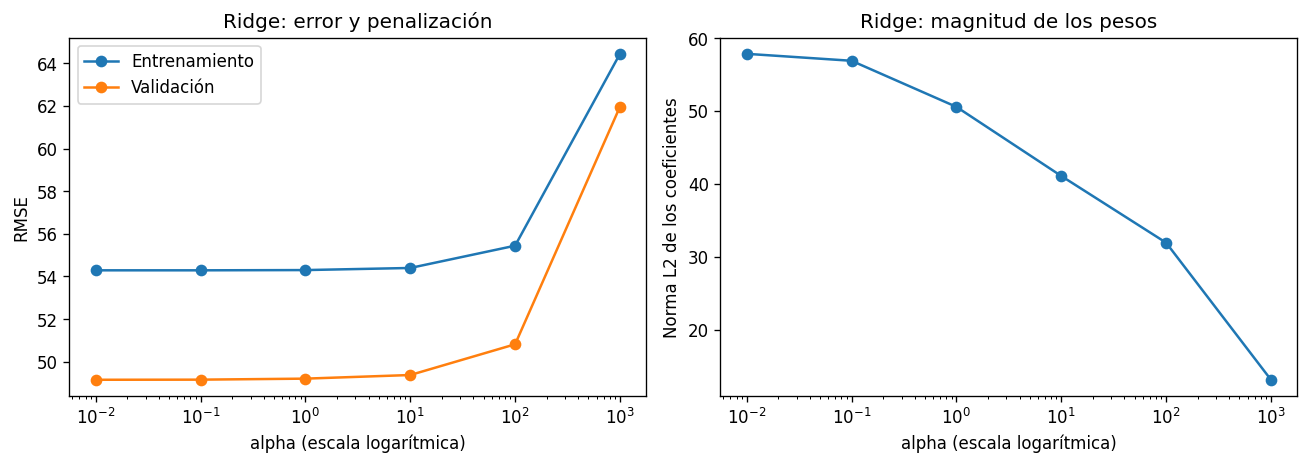

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ridge_regularization["alpha"], ridge_regularization["RMSE de entrenamiento"], marker="o", label="Entrenamiento")
axes[0].plot(ridge_regularization["alpha"], ridge_regularization["RMSE de validación"], marker="o", label="Validación")
axes[0].set_xscale("log")
axes[0].set_xlabel("alpha (escala logarítmica)")
axes[0].set_ylabel("RMSE")
axes[0].set_title("Ridge: error y penalización")
axes[0].legend()
axes[1].plot(ridge_regularization["alpha"], ridge_regularization["Norma L2 de coeficientes"], marker="o")
axes[1].set_xscale("log")
axes[1].set_xlabel("alpha (escala logarítmica)")
axes[1].set_ylabel("Norma L2 de los coeficientes")
axes[1].set_title("Ridge: magnitud de los pesos")
plt.tight_layout()
plt.show()

### Lasso: penalización, coeficientes y errores

In [ ]:
lasso_regularization_rows = []
lasso_coefficient_rows = []
for row in reg_candidates['Lasso']:
    coefficients = row["modelo"].named_steps["regressor"].coef_
    lasso_regularization_rows.append({
        "alpha": row["Parámetros"]["alpha"],
        "RMSE de entrenamiento": row["RMSE de entrenamiento"],
        "RMSE de validación": row["RMSE"],
        "Norma L2 de coeficientes": np.linalg.norm(coefficients),
        "Coeficientes nulos": np.count_nonzero(coefficients == 0),
    })
    lasso_coefficient_rows.append({
        "alpha": row["Parámetros"]["alpha"],
        **dict(zip(X_diabetes.columns, coefficients)),
    })
lasso_regularization = pd.DataFrame(lasso_regularization_rows)
lasso_coefficients = pd.DataFrame(lasso_coefficient_rows)
display(lasso_regularization.round(3))
display(lasso_coefficients.round(3))

alpha,RMSE de entrenamiento,RMSE de validación,Norma L2 de coeficientes,Coeficientes nulos
0.001,54.285,49.150,57.817,0
0.010,54.285,49.157,56.563,0
0.100,54.302,49.203,49.319,0
1.000,54.473,49.525,41.095,2
10.000,57.386,53.821,30.819,6
100.000,77.331,76.161,0.000,10


alpha,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0.001,0.853,-10.784,28.356,17.357,-31.429,16.815,0.627,6.794,28.305,1.487
0.010,0.865,-10.758,28.380,17.338,-30.120,15.832,0.007,6.546,27.820,1.484
0.100,0.902,-10.517,28.588,17.186,-21.746,9.256,-3.421,5.548,24.598,1.469
1.000,0.112,-8.545,28.765,16.263,-5.822,-0.000,-10.836,0.000,19.278,0.970
10.000,0.000,-0.000,26.201,8.586,-0.000,-0.000,-3.970,0.000,13.185,0.000
100.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000


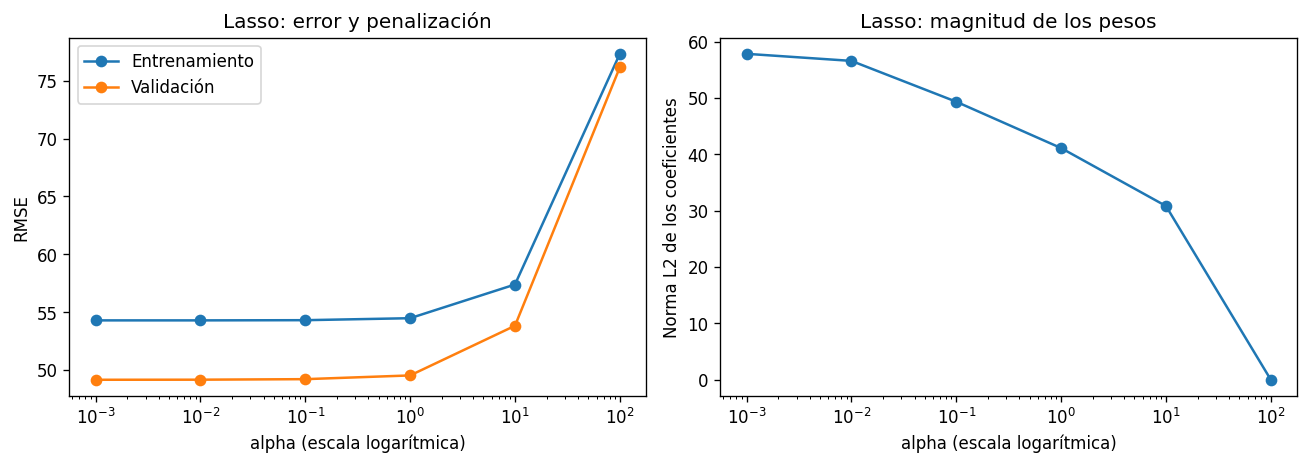

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(lasso_regularization["alpha"], lasso_regularization["RMSE de entrenamiento"], marker="o", label="Entrenamiento")
axes[0].plot(lasso_regularization["alpha"], lasso_regularization["RMSE de validación"], marker="o", label="Validación")
axes[0].set_xscale("log")
axes[0].set_xlabel("alpha (escala logarítmica)")
axes[0].set_ylabel("RMSE")
axes[0].set_title("Lasso: error y penalización")
axes[0].legend()
axes[1].plot(lasso_regularization["alpha"], lasso_regularization["Norma L2 de coeficientes"], marker="o")
axes[1].set_xscale("log")
axes[1].set_xlabel("alpha (escala logarítmica)")
axes[1].set_ylabel("Norma L2 de los coeficientes")
axes[1].set_title("Lasso: magnitud de los pesos")
plt.tight_layout()
plt.show()

## Resultados

### Paso 6. Evaluación final en prueba

Las configuraciones ya están congeladas. Las reentrenamos con entrenamiento y validación juntos y evaluamos sobre los mismos 89 pacientes de prueba. Las transformaciones se vuelven a ajustar con esos datos de desarrollo; los pacientes de prueba siguen excluidos. MAE y RMSE se calculan en la escala original del objetivo, incluido el MLP.

In [ ]:
X_reg_development = pd.concat([X_reg_train, X_reg_validation])
y_reg_development = pd.concat([y_reg_train, y_reg_validation])
final_reg_models = {}
reg_predictions_test = {}
reg_test_rows = []
for name, selected in best_reg_validation.items():
    final_model = clone(selected["modelo"])
    final_model.fit(X_reg_development, y_reg_development)
    prediction = final_model.predict(X_reg_test)
    final_reg_models[name] = final_model
    reg_predictions_test[name] = prediction
    reg_test_rows.append({"Modelo": name, **regression_metrics(y_reg_test, prediction)})
reg_results_test = pd.DataFrame(reg_test_rows)
display(reg_results_test.round(3))

Modelo,MAE,RMSE,R²
Regresión lineal,46.677,56.648,0.445
Ridge,46.677,56.649,0.445
Lasso,46.678,56.649,0.445
kNN de regresión,45.472,56.949,0.439
Árbol de regresión,49.215,62.710,0.320
Random Forest de regresión,45.251,55.486,0.468
Gradient Boosting de regresión,45.534,55.403,0.469
MLP de regresión,45.845,55.460,0.468


### Referencia con una predicción constante

Como propone la clase, también medimos qué pasa si para todos los pacientes predecimos la media del objetivo de entrenamiento y validación. Esto ayuda a valorar si los modelos aportan algo frente a una regla muy simple. Esta referencia usa la media de desarrollo; la fórmula de R² usa la media del conjunto evaluado, por lo que su R² de prueba no tiene que ser exactamente cero.

In [ ]:
reg_baseline = DummyRegressor(strategy="mean")
reg_baseline.fit(X_reg_development, y_reg_development)
reg_baseline_metrics = regression_metrics(y_reg_test, reg_baseline.predict(X_reg_test))
display(pd.DataFrame([{"Modelo": "Media de desarrollo", **reg_baseline_metrics}]).round(3))

Modelo,MAE,RMSE,R²
Media de desarrollo,66.823,77.14,-0.029


### Predicciones, residuos y errores grandes

En el gráfico de valores reales frente a predicciones, un punto sobre la diagonal sería un acierto exacto. Definimos el residuo como **valor real menos predicción**: positivo significa que el modelo predijo por debajo del valor real; negativo significa que predijo por encima. El gráfico de residuos muestra si los errores se distribuyen alrededor de cero o dejan patrones visibles.

Para cada modelo solicitamos los dos mayores errores absolutos de prueba y mostramos las variables de esos pacientes. Son ejemplos elegidos por su error, no una muestra representativa de todos los casos.

#### Regresión lineal: valores reales frente a predicciones

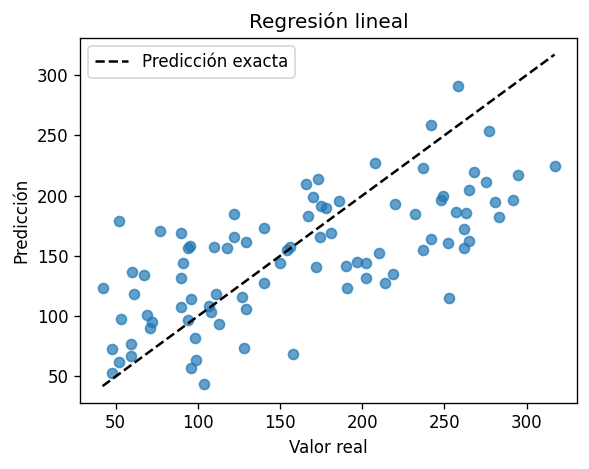

In [ ]:
linear_test_prediction = reg_predictions_test['Regresión lineal']
fig, axis = plt.subplots(figsize=(5, 4))
axis.scatter(y_reg_test, linear_test_prediction, alpha=0.7)
lower = min(y_reg_test.min(), linear_test_prediction.min())
upper = max(y_reg_test.max(), linear_test_prediction.max())
axis.plot([lower, upper], [lower, upper], "--", color="black", label="Predicción exacta")
axis.set_xlabel("Valor real")
axis.set_ylabel("Predicción")
axis.set_title('Regresión lineal')
axis.legend()
plt.tight_layout()
plt.show()

#### Regresión lineal: residuos

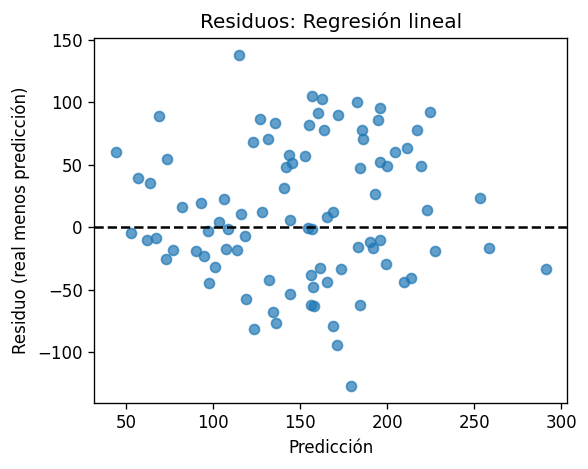

In [ ]:
linear_residuals = y_reg_test.to_numpy() - linear_test_prediction
fig, axis = plt.subplots(figsize=(5, 4))
axis.scatter(linear_test_prediction, linear_residuals, alpha=0.7)
axis.axhline(0, linestyle="--", color="black")
axis.set_xlabel("Predicción")
axis.set_ylabel("Residuo (real menos predicción)")
axis.set_title("Residuos: Regresión lineal")
plt.tight_layout()
plt.show()

#### Regresión lineal: dos errores absolutos grandes

In [ ]:
linear_error_positions = np.argsort(np.abs(linear_residuals))[-2:][::-1]
linear_error_indices = X_reg_test.index[linear_error_positions]
linear_large_errors = pd.DataFrame({
    "Índice de paciente": linear_error_indices,
    "Valor real": y_reg_test.iloc[linear_error_positions].to_numpy(),
    "Predicción": linear_test_prediction[linear_error_positions],
    "Residuo": linear_residuals[linear_error_positions],
    "Error absoluto": np.abs(linear_residuals[linear_error_positions]),
})
display(linear_large_errors.round(3))
display(X_reg_test.loc[linear_error_indices].T.reset_index(names="Variable"))

Índice de paciente,Valor real,Predicción,Residuo,Error absoluto
304,253.0,114.695,138.305,138.305
380,52.0,179.140,-127.140,127.140


Variable,304,380
age,60.0000,53.0000
sex,2.0000,1.0000
bmi,22.8000,28.8000
bp,110.0000,111.6700
s1,245.0000,145.0000
s2,189.8000,87.2000
s3,39.0000,46.0000
s4,6.0000,3.1500
s5,4.3944,4.0775
s6,88.0000,85.0000


#### MLP de regresión: valores reales frente a predicciones

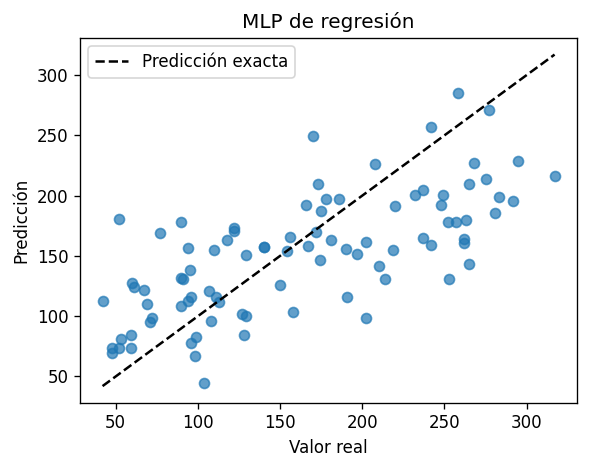

In [ ]:
reg_mlp_test_prediction = reg_predictions_test['MLP de regresión']
fig, axis = plt.subplots(figsize=(5, 4))
axis.scatter(y_reg_test, reg_mlp_test_prediction, alpha=0.7)
lower = min(y_reg_test.min(), reg_mlp_test_prediction.min())
upper = max(y_reg_test.max(), reg_mlp_test_prediction.max())
axis.plot([lower, upper], [lower, upper], "--", color="black", label="Predicción exacta")
axis.set_xlabel("Valor real")
axis.set_ylabel("Predicción")
axis.set_title('MLP de regresión')
axis.legend()
plt.tight_layout()
plt.show()

#### MLP de regresión: residuos

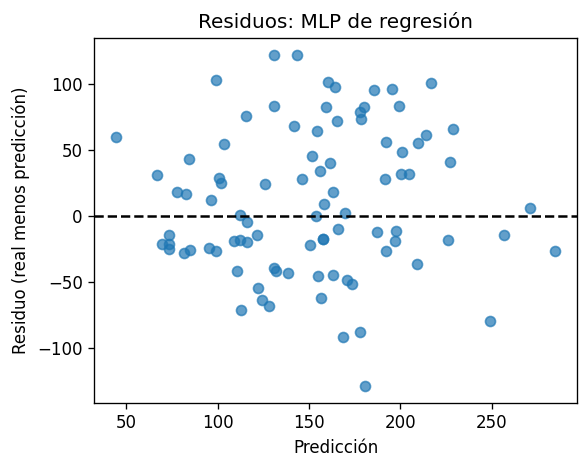

In [ ]:
reg_mlp_residuals = y_reg_test.to_numpy() - reg_mlp_test_prediction
fig, axis = plt.subplots(figsize=(5, 4))
axis.scatter(reg_mlp_test_prediction, reg_mlp_residuals, alpha=0.7)
axis.axhline(0, linestyle="--", color="black")
axis.set_xlabel("Predicción")
axis.set_ylabel("Residuo (real menos predicción)")
axis.set_title("Residuos: MLP de regresión")
plt.tight_layout()
plt.show()

#### MLP de regresión: dos errores absolutos grandes

In [ ]:
reg_mlp_error_positions = np.argsort(np.abs(reg_mlp_residuals))[-2:][::-1]
reg_mlp_error_indices = X_reg_test.index[reg_mlp_error_positions]
reg_mlp_large_errors = pd.DataFrame({
    "Índice de paciente": reg_mlp_error_indices,
    "Valor real": y_reg_test.iloc[reg_mlp_error_positions].to_numpy(),
    "Predicción": reg_mlp_test_prediction[reg_mlp_error_positions],
    "Residuo": reg_mlp_residuals[reg_mlp_error_positions],
    "Error absoluto": np.abs(reg_mlp_residuals[reg_mlp_error_positions]),
})
display(reg_mlp_large_errors.round(3))
display(X_reg_test.loc[reg_mlp_error_indices].T.reset_index(names="Variable"))

Índice de paciente,Valor real,Predicción,Residuo,Error absoluto
380,52.0,180.877,-128.877,128.877
304,253.0,130.651,122.349,122.349


Variable,380,304
age,53.0000,60.0000
sex,1.0000,2.0000
bmi,28.8000,22.8000
bp,111.6700,110.0000
s1,145.0000,245.0000
s2,87.2000,189.8000
s3,46.0000,39.0000
s4,3.1500,6.0000
s5,4.0775,4.3944
s6,85.0000,88.0000


## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
   - Gradient Boosting tuvo el menor RMSE de prueba (55.403) y el mayor R² (0.469). Random Forest tuvo el menor MAE (45.251). Por eso la respuesta depende de la métrica: con el criterio principal de este experimento, RMSE, Gradient Boosting quedó primero. La diferencia frente al MLP (RMSE 55.460) y Random Forest (55.486) es pequeña; una sola partición no demuestra que ese orden vaya a repetirse siempre. Todos mejoraron frente a la referencia constante, cuyo RMSE fue 77.140.

2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
   - MAE promedia el tamaño absoluto de los errores. RMSE los eleva al cuadrado antes de promediar, así que los errores grandes pesan más. Aquí Random Forest tuvo mejor MAE que Gradient Boosting, pero un RMSE algo mayor. También kNN redujo el MAE frente a la regresión lineal (45.472 frente a 46.677), aunque su RMSE fue mayor (56.949 frente a 56.648). Esto muestra que mejorar el error absoluto medio no garantiza mejorar el error cuadrático.

3. ¿Cómo se interpreta un R² negativo?
   - Significa que el modelo tiene más error cuadrático que predecir para todos la media de los valores reales del conjunto evaluado. No significa que el error sea negativo ni que las variables tengan una relación negativa. Ninguno de los ocho regresores tuvo R² negativo en prueba, pero la referencia que predice la media de desarrollo obtuvo -0.029: esa media no coincide exactamente con la media de los pacientes de prueba. Un R² de 0.469, como el de Gradient Boosting, indica una reducción aproximada del 46.9 % del error cuadrático respecto a la media de prueba; no significa acertar el 46.9 % de los pacientes.

4. ¿Qué efecto tuvo aumentar la regularización?
   - En Ridge, la norma L2 de los coeficientes bajó de 57.847 a 13.132 al aumentar `alpha` de 0.01 a 1000. Su RMSE de validación subió de 49.150 a 61.959. En Lasso, al pasar de 0.001 a 100, los diez coeficientes terminaron en cero y el RMSE de validación subió de 49.150 a 76.161. En esta separación, las penalizaciones fuertes quitaron demasiado ajuste y produjeron subajuste. La validación eligió las menores intensidades probadas: 0.01 para Ridge y 0.001 para Lasso. Eso no demuestra que penalizar sea siempre perjudicial ni que hayamos encontrado el mejor valor posible fuera de la lista.

5. ¿Qué puede explicar los errores grandes?
   - Los dos modelos mostraron sus mayores errores en los mismos pacientes, 304 y 380. Para el paciente 304, el valor real fue 253 y la regresión lineal predijo 114.695; el MLP predijo 130.651. Ambos quedaron bastante por debajo. Para el paciente 380, el valor real fue 52 y ambos predijeron alrededor de 180, bastante por encima. Estos casos muestran que las diez variables no bastaron para predecir bien todas las respuestas. Podrían influir variaciones individuales no recogidas, ruido o relaciones que los modelos no aprendieron, pero las tablas por sí solas no permiten identificar la causa. Tampoco llamaría a esos pacientes datos incorrectos solo porque el error sea grande.

6. ¿Un coeficiente predictivo demuestra una relación causal?
   - No. Un coeficiente describe cómo cambia la predicción al variar una característica manteniendo las demás constantes, dentro del modelo ajustado. Puede reflejar asociaciones, correlaciones entre variables o información incompleta. No demuestra que intervenir sobre esa característica cambie la progresión de la enfermedad en la misma cantidad. Para sostener una conclusión causal necesitaríamos un diseño y supuestos adicionales; esta práctica evalúa predicción.

### Análisis de regularización

La idea de clase es limitar la complejidad para mejorar la generalización, pero aumentar la penalización no mejora automáticamente el resultado. En nuestras tablas, el RMSE de entrenamiento crece al restringir los coeficientes y el de validación también empeora. Aquí domina la pérdida de capacidad de ajuste; no observamos una mejora de validación por aplicar una penalización fuerte.

Ridge conservó los diez coeficientes distintos de cero. Lasso dejó dos en cero con `alpha=1`, seis con `alpha=10` y los diez con `alpha=100`. En ese último caso solo queda el intercepto, equivalente a predecir un valor constante. Las tablas de coeficientes permiten ver ese cambio directamente. Con las intensidades seleccionadas, Ridge y Lasso se comportaron casi igual que la regresión lineal en prueba, porque la penalización fue muy pequeña.

### Capacidad del modelo y límites de la comparación

El MLP, los vecinos y los árboles pueden representar relaciones no lineales. Esa flexibilidad no garantizó menor error: el árbol tuvo RMSE 62.710, peor que la regresión lineal. El MLP sí redujo RMSE frente al modelo lineal en esta partición, aunque eso no justifica concluir que siempre será preferible. La capa oculta utiliza una activación no lineal; la salida de regresión entrega un número, no probabilidades de clases.

En los gráficos de valores reales frente a predicciones, ambos modelos tienden a quedarse cortos para varios valores reales altos y a predecir demasiado para algunos valores bajos. La nube no sigue exactamente la diagonal. Los residuos aparecen a ambos lados de cero y hay errores grandes de ambos signos; añadir una capa oculta no eliminó esos casos difíciles. Estos gráficos muestran dónde falla la predicción, pero no identifican por sí solos qué variable o proceso produjo cada error.

Las decisiones se tomaron con validación y las métricas finales con los mismos 89 pacientes de prueba. No reajustamos después de ver la prueba. Estas cifras describen un único reparto de un dataset pequeño; no son una garantía de rendimiento para otros pacientes. MAE y RMSE conservan la escala del objetivo, y los gráficos y ejemplos deben leerse junto con las métricas, sin convertir errores o coeficientes en explicaciones clínicas o causales.

## Fuentes utilizadas

- Iván Carrera, [Revisión de Machine Learning](https://github.com/ivan-carrera/ir26b/blob/main/slides/01_revision_ml.pdf): separación de datos y generalización (diapositivas 6-8), métricas de regresión (10), regresión lineal y regularización (14-15), árboles y ensambles (24-27), salida y entrenamiento del MLP (54-57).
- [scikit-learn: Diabetes](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html), para comprobar el significado de las variables y el escalamiento incluido en la carga predeterminada.

La asistencia de IA se utilizó para preparar código y explicaciones.